# QENS and liquid benzene - Using simulation to inform experimental understanding

Hello, Today we are going to analyse a molecular dynamics simulation of liquid benzene and then compare MD calculated QENS observables to real experimental data. Through this we can begin to use the MD simulation as an 'atomistic resolution' proxy of the real QENS data as well as quantifying issues with the forcefield we have used to run the simulation. 

This workshop is loosely based on [this paper](https://pubs.acs.org/jpclcd/article/17/29/8411/5204625/Lost-in-Translation-Simulation-Informed-Bayesian)


Together we will: 

1) Investigate the simulation and provide some quantification of how well it represents real liquid benzene
2) Calculate the QENS observable from the simulation
3) Compare the MD S(Q,$\omega$) with experimental S(Q,$\omega$)

## 1) Investigating the simulation

I have provided a 1ns equilibrated NVT OPLS trajectory for a liquid benzene system at 290K, Let's use ASE to have a look at the first frame of the trajectory!

In [2]:
from pathlib import Path

import numpy as np
from ase.io import read
from ase.visualize import view
from _fig_params import colors
from tqdm import tqdm

DATA = Path("../../Data/benzene")
TRAJ = DATA / "opls_traj_every250_1ns.atom"
TOPO = DATA / "opls_topology.data"

In [3]:
first_frame = read(
    TRAJ,
    specorder=["C", "C", "C", "C", "C", "C", "H", "H", "H", "H", "H", "H"],
    units="real",
)

print("formula:", first_frame.get_chemical_formula())
print("cell (A):", first_frame.cell.lengths().round(3))
view(first_frame, viewer="x3d")

formula: C2058H2058
cell (A): [36.999 36.999 36.999]


**Yup, that does in fact look like a box of benzene**

What density is the simulation at, define a calc_density function to calculate it in kg/m^3 how does this compare to the experimental density?

The two constants below might help 

In [4]:
from ase.units import kg, m


def calc_density(atoms):
    M = atoms.get_masses().sum()
    V = atoms.get_volume()
    rho = (M / kg) / (V / m**3) / 1000
    return rho


print(f"The simulation is at a density of: {calc_density(first_frame)} kgm-3")

The simulation is at a density of: 0.8784480035582056 kgm-3


Ok great we have the density of our simulation and understand the number of molecules etc, let's start to look at the structuring and dynamics, for this we will switch from using ASE to MDAnalysis, ASE is great (especially if we want to do on the fly calculations) but MDAnalysis lazy loads our trajectory so it can be a bit quicker and less memory intensive for large, long trajectories.


[MDAnalysis documentation](https://userguide.mdanalysis.org/stable/index.html)


Load the trajectory into an MDAnalysis universe and check that everything looks ok.

In [5]:
import MDAnalysis as mda

# u = mda.Universe()
u = mda.Universe(TOPO, TRAJ, format="LAMMPSDUMP", dt=0.25)
print("Let's check we have correctly loaded the universe")
print(f"No of atoms: {len(u.atoms)}")
print(f"No of frames: {len(u.trajectory)}")
print(
    f"Atom types: {u.atoms.types} <- This will be important when we want to calculate rdfs and diffusion"
)

Let's check we have correctly loaded the universe
No of atoms: 4116
No of frames: 4000
Atom types: ['1' '2' '3' ... '10' '11' '12'] <- This will be important when we want to calculate rdfs and diffusion


<details>
<summary><b>Show solution</b></summary>

```python
u = mda.Universe(TOPO, TRAJ, format="LAMMPSDUMP", dt = 0.25)
```

</details>

## Simlation structure

Great, let's calculate the centre centre RDF for the benzene molecules, we can then compare to the 'experimental' RDF calculated from ESR from total neutron scattering

The experimental rdf was taken from [this paper](https://www.tandfonline.com/doi/pdf/10.1080/00268976.2019.1631496)


MDAnalysis doesn't have an inbuilt centre centre RDF calculator so here we use a method I stole from a github issue

In [6]:
from MDAnalysis.analysis import rdf


class BeadGroup(object):
    def __init__(self, groups):
        self._groups = groups

    def __len__(self):
        return len(self._groups)

    @property
    def positions(self):
        return np.array(
            [g.center_of_mass(unwrap=True) for g in self._groups], dtype=np.float32
        )

    @property
    def universe(self):
        return self._groups[0].universe


types = "type 1 2 3 4 5 6 7 8 9 10 11 12"  # Each atom in a molecule is labelled type 1 to 12 (this is just an artifact of how the simulation was set up)
# see: https://userguide.mdanalysis.org/stable/selections.html for more info on atom selection

COM = u.select_atoms(types)
com_groups12 = COM.fragments  # if you have bond information
c12 = BeadGroup(com_groups12)
rdf_opls = rdf.InterRDF(c12, c12, range=(0, 15), exclusion_block=(1, 1), verbose=True)
rdf_opls.run(start=None, stop=None, step=10)

  0%|          | 0/400 [00:00<?, ?it/s]

**Compare your opls calculated RDF to the experimentally generated one below.**


How many frames do you need to generate a nicely converged RDF? 

What size simulation do you need for an RDF to 15A? 

Quantify differences between the two RDFs how could you investigate the structuring further? 

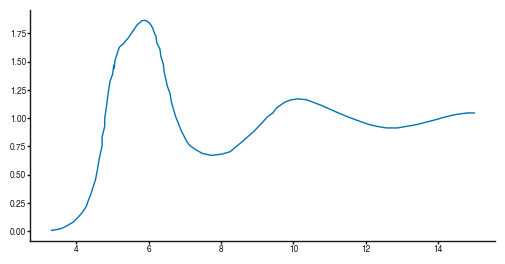

In [7]:
import matplotlib.pyplot as plt

exp_rdf = np.loadtxt(DATA / "experimental_rdf.txt")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(exp_rdf[:, 0], exp_rdf[:, 1], color=colors[0], label="ESR from TSR")

<details>
<summary><b>Show solution</b></summary>

```python
exp_rdf = np.loadtxt(DATA / "experimental_rdf.txt")

fig,ax = plt.subplots(figsize = (6,3))
ax.plot(exp_rdf[:,0],exp_rdf[:,1], color = colors[0], label = 'ESR from TSR')
ax.plot(rdf_opls.results.bins,rdf_opls.results.rdf, color = colors[3], label = 'OPLS')
ax.set_xlabel("Distance (A)") 
ax.set_ylabel("g(r)")
ax.legend()
```

</details>


## Simulation dynamics


QENS probs a wide variety of time scales from  ~1ps to ~1ns and so covers a very wide range of dynamics

For benzene this means QENS covers the rotational motion of the benzene molecules (~1-10ps) as well as Fickian diffusion (~50+ ps)

Initially we are going to calculate the fickian diffusion coefficient of the simulation

### Diffusion

The fickian diffusion coefficient of a pure bulk liquid can be calculated from the gradient of the Mean Squared Displacement (MSD) line through the Einstein relation via:

$$
D = \lim_{t \to \infty} \frac{1}{6t} \left\langle \left| \mathbf{r}_i(t) - \mathbf{r}_i(0) \right|^2 \right\rangle
$$

where $\mathbf{r}_i(t)$ is the position of molecule $i$ at time $t$, and the average is taken over all $N$ molecules and time origins $t_0$:

$$
\text{MSD}(t) = \frac{1}{N} \sum_{i=1}^{N} \left\langle \left| \mathbf{r}_i(t_0 + t) - \mathbf{r}_i(t_0) \right|^2 \right\rangle_{t_0}
$$

Fitting $\text{MSD}(t) = m\,t + c$ over the linear (diffusive) regime gives:

$$
D = \frac{m}{6}
$$

This all seems pretty simple right, but there is a catch. For a real simulation, with a limited number of atoms and simulation length, the observed value of the diffusion coefficient will vary upon repetition of a given simulation... 

Luckily, there are python packages that can help us efficiently quantify this uncertainty within our diffusion coefficient (using only a single simulation)


[kinisi](https://kinisi.readthedocs.io/en/latest/index.html) is one such package, and today we shall use it to calculate our simulation diffusion coefficient


Using 

https://kinisi.readthedocs.io/en/latest/ase_COG.html and https://kinisi.readthedocs.io/en/latest/mdanalysis.html (for MDA in kinisi syntax)

calculate and plot the MSD curve and Diffusion coefficient for our benzene trajectory


**HINT: if it is taking a long time to run, try setting a custom dt**


In [8]:
from kinisi.analyze import DiffusionAnalyzer
import scipp as sc

molecules = np.arange(0, len(u.atoms)).reshape(-1, 12)
masses = u.atoms.masses[0:12]
dt = sc.arange(
    dim="time interval",
    start=250 * sc.Unit("fs"),
    stop=(250 * len(u.trajectory)) * sc.Unit("fs"),
    step=1000 * sc.Unit("fs"),
)
p_params = {
    "specie_indices": sc.array(
        dims=["particle", "atoms in particle"],
        values=molecules,
        unit=sc.Unit("dimensionless"),
    ),
    "masses": sc.array(dims=["atoms in particle"], values=masses),
    "time_step": 1.0 * sc.Unit("fs"),
    "dt": dt,
    "step_skip": 250 * sc.Unit("dimensionless"),
    "progress": True,
}

start_of_diffusion = 150 * sc.Unit("ps")
diff = DiffusionAnalyzer.from_universe(u, **p_params)
diff.diffusion(start_of_diffusion, random_state=np.random.RandomState(42))

Likelihood Sampling: 100%|██████████| 1500/1500 [00:01<00:00, 975.80it/s] 


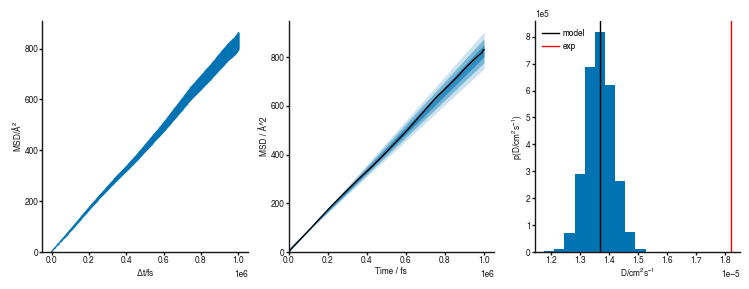

In [ ]:
def uncertainty_plotter(kinisi_object, axis=None, color="#0173B2"):
    credible_intervals = [[16, 84], [2.5, 97.5], [0.15, 99.85]]
    alpha = [0.6, 0.4, 0.2]

    if axis is None:
        fig, axis = plt.subplots()

    axis.plot(kinisi_object.dt.values, kinisi_object.msd.values, "k-")
    for i, ci in enumerate(credible_intervals):
        axis.fill_between(
            kinisi_object.dt.values,
            *np.percentile(kinisi_object.distributions, ci, axis=1),
            alpha=alpha[i],
            color=color,
            lw=0,
        )
    axis.set_xlabel(f"Time / {kinisi_object.dt.unit}")
    axis.set_ylabel(f"MSD / {kinisi_object.msd.unit}")
    axis.set_xlim(0, None)
    axis.set_ylim(0, None)


fig, ax = plt.subplots(1, 3)
fig.set_size_inches(9, 3)
ax[0].errorbar(
    diff.dt.values, diff.msd.values, np.sqrt(diff.msd.variances), color=colors[0]
)
ax[0].set_ylabel("MSD/Å$^2$")
ax[0].set_xlabel(r"$\Delta t$/fs")
ax[0].set_ylim(0, None)

uncertainty_plotter(diff, ax[1], color=colors[0])
ax[1].set_ylim(0, None)
ax[2].hist(diff.D.values, density=True, color=colors[0])
ax[2].axvline(diff.D.mean().values, c="k", label="model")
ax[2].set_xlabel("$D$/cm$^2$s$^{-1}$")
ax[2].set_ylabel("$p(D$/cm$^2$s$^{-1})$")
ax[2].axvline(10**-8.74 * 10000, c="r", label="exp")
ax[2].legend()

<details>
<summary><b>Show solution</b></summary>

```python
from kinisi.analyze import DiffusionAnalyzer
import scipp as sc

molecules = np.arange(0,len(u.atoms)).reshape(-1,12)
masses = u.atoms.masses[0:12]
dt = sc.arange(dim='time interval', start=250 * sc.Unit('fs'),
                stop=(250*len(u.trajectory)) * sc.Unit('fs'),
                step=1000 * sc.Unit('fs'))
p_params = {
        'specie_indices': sc.array(dims=['particle', 'atoms in particle'],
                values=molecules,
                unit=sc.Unit('dimensionless')),
        'masses': sc.array(dims = ['atoms in particle'],values=masses),
        'time_step': 1.0 * sc.Unit('fs'),
        'dt': dt,
        'step_skip': 250 * sc.Unit('dimensionless'),
        'progress': True}

start_of_diffusion = 150 * sc.Unit('ps')
diff = DiffusionAnalyzer.from_universe(u, **p_params)
diff.diffusion(start_of_diffusion, random_state=np.random.RandomState(42))

def uncertainty_plotter(kinisi_object, 
                        axis = None,
                        color = '#0173B2'):
    credible_intervals = [[16, 84], [2.5, 97.5], [0.15, 99.85]]
    alpha = [0.6, 0.4, 0.2]

    if axis == None:
        fig, axis = plt.subplots()

    axis.plot(kinisi_object.dt.values, kinisi_object.msd.values, 'k-')
    for i, ci in enumerate(credible_intervals):
        axis.fill_between(kinisi_object.dt.values,
                        *np.percentile(kinisi_object.distributions, ci, axis=1),
                        alpha=alpha[i],
                        color=color,
                        lw=0)
    axis.set_xlabel(f'Time / {kinisi_object.dt.unit}')
    axis.set_ylabel(f'MSD / {kinisi_object.msd.unit}')
    axis.set_xlim(0, None)
    axis.set_ylim(0, None)



fig, ax = plt.subplots(1,3)
fig.set_size_inches(9,3)
ax[0].errorbar(diff.dt.values, diff.msd.values, np.sqrt(diff.msd.variances), color = colors[0])
ax[0].set_ylabel('MSD/Å$^2$')
ax[0].set_xlabel(r'$\Delta t$/fs')
ax[0].set_ylim(0,None)

uncertainty_plotter(diff, ax[1], color = colors[0])
ax[1].set_ylim(0,None)
ax[2].hist(diff.D.values, density=True, color = colors[0])
ax[2].axvline(diff.D.mean().values, c='k',label = 'model')
ax[2].set_xlabel('$D$/cm$^2$s$^{-1}$')
ax[2].set_ylabel('$p(D$/cm$^2$s$^{-1})$')
ax[2].axvline(10**-8.74*10000, c='r', label = 'exp')
ax[2].legend()

```

</details>


### Rotational Dynamics

We can also begin to understand the rotational dynamics of the benzene molecules. Benzene is a planar **symmetric top** ($D_{6h}$ symmetry), so its rotation can be separated into two principal motions:

- **Spinning**, rotation about the $C_6$ axis perpendicular to the ring, like a spinning record
- **Tumbling (flipping)** , rotation about an axis lying *in* the ring plane, like a coin toss



#### Defining Molecular Vectors

Label the ring carbons C0–C5 consecutively around the ring, with positions $\mathbf{c}_0, \dots, \mathbf{c}_5$.

**Normal vector**, perpendicular to the ring i.e. (along the $C_6$ axis):

$$
\hat{\mathbf{n}} = \frac{(\mathbf{c}_4-\mathbf{c}_0)\times(\mathbf{c}_5-\mathbf{c}_2)}{\left|(\mathbf{c}_4-\mathbf{r}_0)\times(\mathbf{c}_5-\mathbf{r}_2)\right|}
$$

Any two orthogonal vectors in the plane of the benzene will work! 


**In-plane vector**, along the *para* i.e.  C0 → C4 axis:

$$
\hat{\mathbf{p}} = \frac{\mathbf{c}_4-\mathbf{c}_0}{\left|\mathbf{c}_4-\mathbf{c}_0\right|}
$$

| Vector | Affected by spinning? | Affected by tumbling? |
|:---:|:---:|:---:|
| $\hat{\mathbf{n}}$ | ✗ | ✓ |
| $\hat{\mathbf{p}}$ | ✓ | ✓ |

$\hat{\mathbf{n}}$ therefore isolates tumbling, while $\hat{\mathbf{p}}$ reports on both motions together.


#### Reorientational Correlation Functions

We can quantify how quickly each vector decorrelates using the **second-order Legendre polynomial**,

$$
P_2(x) = \tfrac{1}{2}\left(3x^2 - 1\right),
$$

to define the reorientational correlation function

$$
C_2(t) = \Big\langle P_2\big(\hat{\mathbf{u}}_i(t_0)\cdot\hat{\mathbf{u}}_i(t_0+t)\big)\Big\rangle_{i,\,t_0},
$$

averaged over all molecules $i$ and time origins $t_0$, where $\hat{\mathbf{u}}$ is either $\hat{\mathbf{n}}$ or $\hat{\mathbf{p}}$. By construction $C_2(0) = 1$, and $C_2(t) \to 0$ once the orientations are fully randomised.

We can then connect our parameters from $P_2$ to rotational diffusion and eventually to our QENS signal 

**You now have everything you should need to write some code to calculate the rotational autocorrelation for the benzene molecule along these two axis, have a go at writing some functions to define the necessary vectors and then calculate $C_2(t)$ in 10ps windows!**


In order to investigate rotation we will need a trajectory sampled more frequently than 250fs, one has been provided for you!
First load the trajectory in a new universe

In [10]:
TRAJ_ROT = DATA / "opls_traj_every50_250ps.atom"
u_rot = mda.Universe(TOPO, TRAJ_ROT, format="LAMMPSDUMP", dt=0.05)

Now write a function to select the correct unit vectors in the benzene: 

In [11]:
def normalized(a, axis=-1, order=2):
    """
    normalise vector over final axis, shamelessly stolen from stack overflow
    """
    l2 = np.atleast_1d(np.linalg.norm(a, order, axis))
    l2[l2 == 0] = 1
    return a / np.expand_dims(l2, axis)


def vector_maker(atom_positions):
    """
    Choses bezene vectors based on:

    #     0 - 1
    #   5       2
    #     4 - 3

    Parameters
    ----------
    atom_positions : ndarray
        Array of shape (num_molecules, num_atoms, 3) containing 3d atom positions

    Returns
    -------
    vec_0 : ndarray
        Vector in the plan of benzene
    vec_90 : ndarray
        Vector orthogonal to benzene plane
    """
    # Vector between 4th and 0th benzene, straight line down benzene
    vec_0 = normalized(atom_positions[:, 4] - atom_positions[:, 0])
    # Vector between 1st and 2nd benzene- within the plane of the benzene
    vec_1 = normalized(atom_positions[:, 5] - atom_positions[:, 2])
    vec_90 = normalized(np.cross(vec_0, vec_1))
    return vec_0, vec_90

<details>
<summary><b>Show solution</b></summary>

```python
def normalized(a, axis=-1, order=2):
    '''
    normalise vector over final axis, shamelessly stolen from stack overflow
    '''
    l2 = np.atleast_1d(np.linalg.norm(a, order, axis))
    l2[l2 == 0] = 1
    return a / np.expand_dims(l2, axis)


def vector_maker(atom_positions):
    ''' 
    Choses bezene vectors based on: 

    #     0 - 1 
    #   5       2
    #     4 - 3
    
    Parameters
    ----------
    atom_positions : ndarray
        Array of shape (num_molecules, num_atoms, 3) containing 3d atom positions

    Returns
    -------
    vec_0 : ndarray
        Vector in the plan of benzene
    vec_90 : ndarray
        Vector orthogonal to benzene plane  
    '''
    # Vector between 4th and 0th benzene, straight line down benzene
    vec_0 = normalized(atom_positions[:, 3] - atom_positions[:, 0])
    # Vector between 1st and 2nd benzene- within the plane of the benzene
    vec_1 = normalized(atom_positions[:, 1] - atom_positions[:, 4])
    vec_90 = normalized(np.cross(vec_0, vec_1))
    return vec_0, vec_90

```

</details>

Now using the above functions we can select a window and calculate the rotational autocorrelation over this window, write a function or do to do this

In [12]:


def calc_autocorr(vecs_t0, vecs_t):
    """
    Calculates rotational autocorrelation based on the second order legendre polynomial:
    G_pheta(x) = <0.5*[3*cos^2(a(t)) - 1]>
    """
    cos_at = np.einsum("ij,ij->i", vecs_t0, vecs_t)
    autocorr_x = 0.5 * (3 * cos_at**2 - 1)
    autocorr = np.mean(autocorr_x)
    return autocorr


def rotational_ac_calc(
    universe,
    window_size=50,
    atom_types="type 1 2 3 4 5 6 7 8 9 10 11 12",
    N_frames=None,
):
    if N_frames is None:
        N_frames = len(universe.trajectory)

    universe.trajectory[0]
    benzs = universe.select_atoms(atom_types).fragments

    if N_frames % window_size != 0:
        N_frames = window_size * (N_frames // window_size)
        print(f"Using first {N_frames} frames")

    rac0 = np.zeros(N_frames)
    rac90 = np.zeros(N_frames)

    for ts in tqdm(range(N_frames)):
        universe.trajectory[ts]
        if ts % window_size == 0:
            atom_pos_t0 = np.array([frag.positions for frag in benzs])
            vec0_t0, vec90_t0 = vector_maker(atom_pos_t0)

        atom_pos_t = np.array(
            [frag.positions for frag in benzs]
        )  # Shape (num_molecules, num_atoms, 3)
        vec0_t, vec90_t = vector_maker(atom_pos_t)

        rac0[ts] = calc_autocorr(vec0_t0, vec0_t)
        rac90[ts] = calc_autocorr(vec90_t0, vec90_t)

    rac0 = rac0.reshape(-1, window_size)
    rac90 = rac90.reshape(-1, window_size)

    return rac0, rac90


rac0, rac90 = rotational_ac_calc(u_rot, window_size=200)

100%|██████████| 5000/5000 [00:30<00:00, 164.64it/s]


Now try plotting your two 2nd order legendre polynmials over ~10ps. 

What do they look like, what can this tell us about the rotation of the benzene?

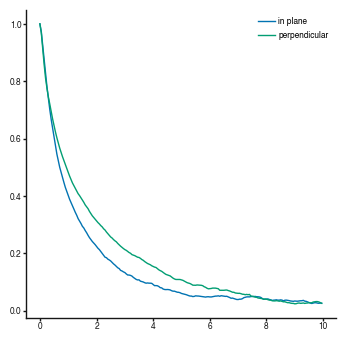

In [13]:
time = np.arange(0, 10.0, 0.05)

fig, ax = plt.subplots(figsize=(4, 4))
ax = [ax]


ax[0].errorbar(time, rac0.mean(axis=0), color=colors[0], label="in plane")
ax[0].errorbar(time, rac90.mean(axis=0), color=colors[1], label="perpendicular")
ax[0].legend()

As we can see the two vectors decorrelate at different rates, this means the rotation of the benzene is anisotropic! This is what is expected from theory and experiment (see [this paper](https://www.tandfonline.com/doi/full/10.1080/00268976.2012.674570) and [this paper](https://www.sciencedirect.com/science/article/pii/0009261472870969))

#### Connecting to Rotational Diffusion

For a symmetric top, with diffusion coefficients $D_\parallel$ (spinning) and $D_\perp$ (tumbling), the two correlation functions take the forms

$$
C_2^{\,n}(t) = e^{-6D_\perp t}
$$

$$
C_2^{\,p}(t) = \tfrac{1}{4}\,e^{-6D_\perp t} + \tfrac{3}{4}\,e^{-(2D_\perp + 4D_\parallel)\,t}
$$

Fitting $C_2^{\,n}$ gives $D_\perp$ directly. With $D_\perp$ then fixed, fitting $C_2^{\,p}$ gives $D_\parallel$. 

The anisotropy ratio ($D_\parallel / D_\perp$) then tells us directly how much faster benzene spins than it tumbles.

If you fancy you can try fitting some exponentials to the data to extract these parameters!


> **Caveat:** Be careful with the first ~ ps as this is likely to be dominated by very fast librations that are not directly connected to the two rotational diffusion coefficients 

**Ok so we have now done some analysis on the structure and dynamics of our simulation, how can we now use the insights we have gained here for the analysis of QENS data?**
**What else could we do to better quantify and understand the simulation?**